# 112장 · 배포·자동화 · 방향과 예시

후보 파일을 받았지만 어떤 이미지를 실행했는지 모르면 같은 서비스로 되돌리기 어렵습니다. 여기서는 배포 설정을 읽고, 실제 배포를 시작하기 전에 무엇을 고정해야 하는지 정합니다.

실행을 확인한 커널은 Python 3.12.15입니다.

Python 3 커널을 선택하고 위에서부터 실행하세요. 팀별 변형을 시도한 뒤 해당 셀 아래에서 예시를 펼쳐 비교할 수 있습니다.

## 설정에서 접근 주소와 데이터 위치 읽기

배포 시안　서버 한 프로세스, JSON 자료 볼륨 p1-json, 호스트 127.0.0.1, 교육용 접근 주체, 이미지 변수명 P1_IMAGE. 실제 이미지 식별자·플랫폼은 미확인입니다. 아래의 고정된 주소는 같은 컴퓨터의 접속 범위를 뜻합니다. 누군가 밖에서 접속했다고 보고하려면 다른 환경에서 실제로 확인한 응답이 필요합니다.

<!-- motion:mount-bridge -->
**컨테이너 경로와 자료 볼륨은 어떻게 이어질까요?**

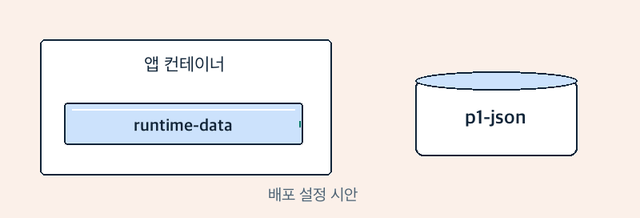

시안은 p1-json을 앱의 runtime-data 위치에 연결합니다. 재배포 뒤 데이터 보존 여부는 같은 볼륨을 연결하고 실제 세션을 다시 읽어 확인합니다.
<!-- /motion -->


### 셀 01 · 설정 사본의 포트와 볼륨 확인

제공 Compose 설정의 p1 항목에서 실제로 지정한 값 두 개만 읽습니다.

In [1]:
p1_service = {'ports': ['127.0.0.1:8104:8104'],
 'volumes': ['p1-json:/app/input106/project-ui/backend/runtime-data'],
 'pull_policy': 'never',
 'image': '${P1_IMAGE:?verified image ID or digest required}'}
print(p1_service["ports"][0])
print(p1_service["volumes"][0])

127.0.0.1:8104:8104
p1-json:/app/input106/project-ui/backend/runtime-data


로컬 8104 포트와 JSON 저장 디렉터리가 보입니다. 설정에 항목이 있다는 사실만으로 프로세스가 실행 중이거나 자료가 저장되었다고 볼 수 없습니다.

## 배포 전후의 관찰 계획 작성하기

준비 순서 예시　검증한 이미지 식별자와 플랫폼 기록 → 해당 복사본으로 상태 확인 요청 → Q01의 답·근거·세션 재조회 → 실패 시 새 쓰기를 멈추고 직전 검증 버전으로 복귀 → 동일 질문과 기존 자료 재조회. 이미지 되돌리기와 바뀐 자료 복구는 별도 작업입니다. 현재 예제에는 외부 응답과 실제 롤백 관찰값이 없습니다.


### 과제 02 · 선택 연습 · 받은 설정에서 미확인 값 찾기

배포 후보에서 값이 None인 필드 이름을 출력하세요. 이어서 팀 메모에 지금 배포할지 보류할지 판단하고, 그 이유를 두 필드에 연결해 한 문장으로 쓰세요.

In [2]:
candidate = {'image_digest': None, 'platform': None}
# 아직 정해지지 않은 필드를 골라 보세요.

<details><summary>정답 코드와 실행 결과 보기</summary>
<pre><code>candidate = {&#x27;image_digest&#x27;: None, &#x27;platform&#x27;: None}
print([key for key, value in candidate.items() if value is None])</code></pre>
<p>실행 결과</p><pre><code>[&#x27;image_digest&#x27;, &#x27;platform&#x27;]</code></pre>
<p>출력은 image_digest와 platform 두 항목입니다. 팀 메모 예시 — 어떤 이미지인지, 어느 플랫폼에서 확인했는지 모두 비어 있어 배포를 보류한다. 보류는 이 값을 읽고 내린 판단입니다.</p>
</details>

## 돌아보기

113장에는 서비스 이미지 식별자와 별개로 자료 볼륨, 쓰기를 멈출 방법, 별도 복구 대상을 알려 주세요. 이 노트북은 설정 읽기만 수행하며 컨테이너 생성이나 공개 배포를 실행하지 않습니다.